In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report


In [ ]:

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())


Saving placement_predict_50k Dataset.csv to placement_predict_50k Dataset (1).csv
Dataset loaded successfully!
Dataset shape: (50000, 32)


,StudentID,Gender,City,CollegeTier,Stream,Specialisation,Hostel,HistoryOfBacklogs,SGPA_Sem1,SGPA_Sem2,...,Publications,AptitudeTestScore,SoftSkillsRating,CodingTestScore,MockInterviewScore,ExtraCurricular,CGPA_Tier,PlacementStatus,IsAnomaly,Salary Package
0,1,Male,Ahmedabad,Tier2,ECE,Networking,No,No,6.02,6.54,...,0,66.7,2.2,49.4,47.8,0,Low,0,0,0.00
1,2,Female,Mumbai,Tier2,ECE,DataScience,Yes,Yes,5.84,5.12,...,0,48.2,2.4,26.7,25.8,0,Low,0,0,0.00
2,3,Male,Kolkata,Tier2,IT,DataScience,Yes,No,4.91,5.29,...,0,73.8,2.8,67.7,41.5,0,Low,1,0,3.89
3,4,Male,Jaipur,Tier1,CS,AI,No,No,7.67,8.03,...,0,69.8,2.7,66.9,48.0,0,Mid,1,0,8.37
4,5,Male,Pune,Tier2,IT,DataScience,Yes,No,8.14,8.97,...,1,73.1,2.1,71.7,61.7,1,High,1,0,18.99



Column names:
['StudentID', 'Gender', 'City', 'CollegeTier', 'Stream', 'Specialisation', 'Hostel', 'HistoryOfBacklogs', 'SGPA_Sem1', 'SGPA_Sem2', 'SGPA_Sem3', 'SGPA_Sem4', 'SGPA_Sem5', 'SGPA_Sem6', 'SGPA_Sem7', 'SGPA_Sem8', 'CGPA', 'AttendancePercent', 'Internships', 'Projects', 'Workshops', 'Certifications', 'Publications', 'AptitudeTestScore', 'SoftSkillsRating', 'CodingTestScore', 'MockInterviewScore', 'ExtraCurricular', 'CGPA_Tier', 'PlacementStatus', 'IsAnomaly', 'Salary Package']


In [ ]:

def create_preprocessor(X):
    numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
    categorical_cols = X.select_dtypes(
        exclude=np.number
    ).columns.tolist()

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, numeric_cols),
        ("cat", categorical_pipeline, categorical_cols)
    ])

    return preprocessor

print("One-Hot Encoding + Scaling pipeline is ready.")


One-Hot Encoding + Scaling pipeline is ready.


In [ ]:

def evaluate_classifier(model, X_train, y_train, X_val, y_val):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    print("Model:", type(model.named_steps["classifier"]).__name__)
    print("Training Accuracy:",
          round(accuracy_score(y_train, train_pred), 4))
    print("Validation Accuracy:",
          round(accuracy_score(y_val, val_pred), 4))

    print("\nClassification Report:")
    print(classification_report(y_val, val_pred, zero_division=0))


In [ ]:

# Select features and binary target
X = df.drop(columns=["PlacementStatus", "CGPA_Tier"])
y = df["PlacementStatus"]

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

binary_lr = Pipeline([
    ("preprocessor", create_preprocessor(X_train)),
    ("classifier", LogisticRegression(max_iter=2000))
])

evaluate_classifier(binary_lr, X_train, y_train, X_val, y_val)


Model: LogisticRegression
Training Accuracy: 0.9975
Validation Accuracy: 0.9968

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00      3429
           1       1.00      1.00      1.00      6571

    accuracy                           1.00     10000
   macro avg       1.00      1.00      1.00     10000
weighted avg       1.00      1.00      1.00     10000



In [ ]:

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

for name, classifier in models.items():
    print("\n" + "=" * 50)
    print(name)

    model_pipeline = Pipeline([
        ("preprocessor", create_preprocessor(X_train)),
        ("classifier", classifier)
    ])

    evaluate_classifier(
        model_pipeline, X_train, y_train, X_val, y_val
    )



Logistic Regression
Model: LogisticRegression
Training Accuracy: 0.9975
Validation Accuracy: 0.9968

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00      3429
           1       1.00      1.00      1.00      6571

    accuracy                           1.00     10000
   macro avg       1.00      1.00      1.00     10000
weighted avg       1.00      1.00      1.00     10000


Random Forest
Model: RandomForestClassifier
Training Accuracy: 1.0
Validation Accuracy: 0.9982

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00      3429
           1       1.00      1.00      1.00      6571

    accuracy                           1.00     10000
   macro avg       1.00      1.00      1.00     10000
weighted avg       1.00      1.00      1.00     10000


Decision Tree
Model: DecisionTreeClassifier
Training Accuracy: 1.0
Validation Accuracy: 0.9963

Clas

In [ ]:

X_cgpa = df.drop(columns=["PlacementStatus", "CGPA_Tier"])
y_cgpa = df["CGPA_Tier"]

X_train_cgpa, X_val_cgpa, y_train_cgpa, y_val_cgpa = train_test_split(
    X_cgpa, y_cgpa,
    test_size=0.2,
    random_state=42,
    stratify=y_cgpa
)

multinomial_lr = Pipeline([
    ("preprocessor", create_preprocessor(X_train_cgpa)),
    ("classifier", LogisticRegression(
        max_iter=2000, solver="lbfgs"
    ))
])

evaluate_classifier(
    multinomial_lr,
    X_train_cgpa, y_train_cgpa,
    X_val_cgpa, y_val_cgpa
)


Model: LogisticRegression
Training Accuracy: 0.9833
Validation Accuracy: 0.9855

Classification Report:
              precision    recall  f1-score   support

        High       1.00      1.00      1.00      3336
         Low       0.98      0.98      0.98      3347
         Mid       0.98      0.97      0.98      3317

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



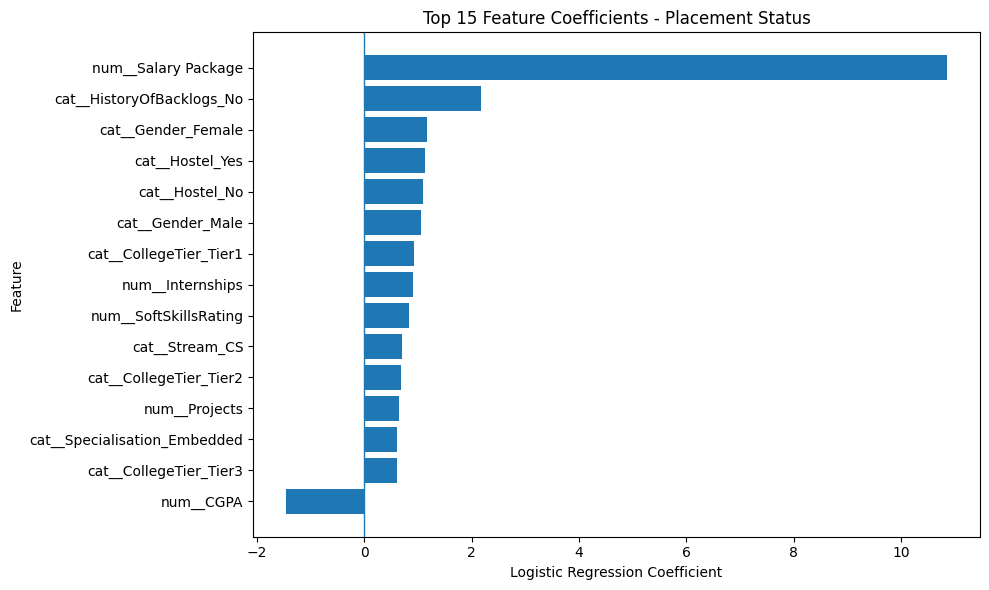

,Feature,Coefficient,AbsoluteCoefficient
22,num__Salary Package,10.857723,10.857723
50,cat__HistoryOfBacklogs_No,2.183148,2.183148
9,num__CGPA,-1.452982,1.452982
23,cat__Gender_Female,1.167742,1.167742
49,cat__Hostel_Yes,1.132780,1.132780
48,cat__Hostel_No,1.098731,1.098731
24,cat__Gender_Male,1.063769,1.063769
35,cat__CollegeTier_Tier1,0.925734,0.925734
11,num__Internships,0.908079,0.908079
17,num__SoftSkillsRating,0.833357,0.833357


In [ ]:

preprocessor = binary_lr.named_steps["preprocessor"]
classifier = binary_lr.named_steps["classifier"]

feature_names = preprocessor.get_feature_names_out()
coefficients = classifier.coef_[0]

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coef_df["AbsoluteCoefficient"] = coef_df["Coefficient"].abs()
top_features = coef_df.nlargest(15, "AbsoluteCoefficient")
top_features = top_features.sort_values("Coefficient")

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Coefficient"])
plt.axvline(0, linewidth=1)
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Top 15 Feature Coefficients - Placement Status")
plt.tight_layout()
plt.show()

display(coef_df.sort_values(
    "AbsoluteCoefficient", ascending=False
).head(15))
